# Лабораторная работа №3
## Классическое выравнивание и N-граммные языковые модели

**Выполнила:** Перминова Анастасия, группа M4221

| Функция | Что получает | Что возвращает |
|---|---|---|
| `viterbi_align(costs, start_state, final_state)` | матрицу стоимостей эмиссии (кадры × состояния), индексы начального и конечного состояний | лучший путь (список индексов состояний по кадрам) и его общую стоимость |
| `BigramLM.train(sentences, k)` | предложения корпуса и параметр сглаживания `k` | обученную модель: словарь, счетчики биграмм и счетчики контекстов |
| `BigramLM.sentence_logprob(sentence)` | одно предложение (строку) | десятичный логарифм вероятности предложения (с учетом `</s>`) |
| `rank_candidates(candidates, weight)` | список кандидатов с `acoustic_log_score` и `lm_log_score`, вес языковой модели | тот же список с добавленным `combined_log_score`, отсортированный по убыванию |

`viterbi_align` (`scripts/viterbi_alignment.py`)

```python
choices = [(state, dp[t - 1][state])]
if state > start_state:
    choices.append((state - 1, dp[t - 1][state - 1]))
previous_state, previous_cost = min(choices, key=lambda item: item[1])
if math.isfinite(previous_cost):
    dp[t][state] = previous_cost + float(costs[t][state])
    back[t][state] = previous_state
```

Чтобы попасть в ячейку «кадр `t` / состояние `state`» можно либо остаться в том же состоянии (`state` на кадре `t-1`), либо перейти из предыдущего (`state-1`). Для начального состояния предыдущего нет, поэтому второй вариант отпадает. `min()` при равных значениях возвращает первый элемент, а вариант «остаться» стоит в списке первым, так что при «ничьей» остаемся в текущем состоянии. Дальше к стоимости лучшего предыдущего прибавляем стоимость эмиссии текущей ячейки и записываем в таблицу `back`, откуда пришли. Это рекуррентная формула `D[t, s] = emission_cost[t, s] + min(D[t-1, s], D[t-1, s-1])`.

`BigramLM.bigram_probability` (`scripts/bigram_lm.py`)

```python
numerator = self.bigram_counts[(previous, word)] + self.k
denominator = self.context_counts[previous] + self.k * vocab_size
```

Это формула add-k: `P(w | h) = (C(h, w) + k) / (C(h) + k·|V|)`. `Counter` для отсутствующих ключей возвращает 0, отсутствующие биграммы получают вероятность `k / (C(h) + k·|V|)`.

`rank_candidates` (`scripts/combine_candidate_scores.py`)

```python
row["combined_log_score"] = acoustic + weight * language
```

Объединенная оценка равна сумме акустической оценки плюс языкоой, умноженной на вес λ.

In [4]:
import csv
import json
import sys
from pathlib import Path

from IPython.display import SVG, display

LAB_ROOT = Path.cwd()
sys.path.insert(0, str(LAB_ROOT))

from scripts.run_lab_03 import run_lab

summary = run_lab(LAB_ROOT / "data", LAB_ROOT / "outputs")
summary

{'alignment_path': [0, 1, 1, 2, 3, 4],
 'alignment_total_cost': 3.0,
 'alternative_path_cost': 3.7,
 'candidate_rankings': {'0.0': ['acoustic_favorite', 'language_favorite'],
  '0.5': ['language_favorite', 'acoustic_favorite'],
  '1.0': ['language_favorite', 'acoustic_favorite']},
 'note': 'Стоимость и акустические баллы синтетические: это учебный пример, а не вывод модели.'}

## Часть A. Выравнивание по алгоритму Витерби

Транскрипция «yes» - это пять состояний: `sil_start → /y/ → /e/ → /s/ → sil_end`. Кадров шесть, то есть на пять состояний приходится один «лишний» кадр, в котором придется остаться в прежнем состоянии. Смотрим на входную матрицу стоимостей эмиссии (чем меньше, тем лучше).

In [5]:
alignment = json.loads((LAB_ROOT / "data" / "toy_alignment_costs.json").read_text(encoding="utf-8"))
states = alignment["state_labels"]
frames = alignment["frame_labels"]
costs = alignment["costs"]

print("кадр  " + "".join(f"{s:>11}" for s in states))
for f, row in zip(frames, costs):
    print(f"{f:<6}" + "".join(f"{v:>11.1f}" for v in row))

кадр    sil_start        /y/        /e/        /s/    sil_end
f1            0.4        9.0        9.0        9.0        9.0
f2            9.0        0.7        9.0        9.0        9.0
f3            9.0        0.5        1.2        9.0        9.0
f4            9.0        9.0        0.6        9.0        9.0
f5            9.0        9.0        9.0        0.5        9.0
f6            9.0        9.0        9.0        9.0        0.3


В каждой строке (кадре) одна ячейка с маленькой стоимостью, а остальные равны 9.0. То есть акустическая модель «уверена», какое состояние должно быть на каждом кадре. Исключение - кадр f3: там мало стоят и `/y/` (0.5), и `/e/` (1.2), поэтому Витерби нужно выбрать, где быть.

Результат работы алгоритма:

In [6]:
path = summary["alignment_path"]
print("Индексы состояний:", path)
print("Лучший путь:      ", " → ".join(states[s] for s in path))
print("Общая стоимость:  ", summary["alignment_total_cost"])
print()

with open(LAB_ROOT / "outputs" / "alignment_path.csv", encoding="utf-8") as f:
    for row in csv.reader(f):
        print(" | ".join(f"{cell:<10}" for cell in row))

Индексы состояний: [0, 1, 1, 2, 3, 4]
Лучший путь:       sil_start → /y/ → /y/ → /e/ → /s/ → sil_end
Общая стоимость:   3.0

frame      | state_index | state_label | emission_cost | path_cost_so_far
f1         | 0          | sil_start  | 0.400      | 0.400     
f2         | 1          | /y/        | 0.700      | 1.100     
f3         | 1          | /y/        | 0.500      | 1.600     
f4         | 2          | /e/        | 0.600      | 2.200     
f5         | 3          | /s/        | 0.500      | 2.700     
f6         | 4          | sil_end    | 0.300      | 3.000     


**Лучший путь:** `sil_start, /y/, /y/, /e/, /s/, sil_end` (индексы `[0, 1, 1, 2, 3, 4]`). **Общая стоимость: 3.0**.

Накопленные стоимости по кадрам (колонка `path_cost_so_far`):

| Кадр | Состояние | Стоимость эмиссии | Накопленная стоимость |
|---|---|---|---|
| f1 | sil_start | 0.4 | 0.4 |
| f2 | /y/ | 0.7 | 1.1 |
| f3 | /y/ | 0.5 | 1.6 |
| f4 | /e/ | 0.6 | 2.2 |
| f5 | /s/ | 0.5 | 2.7 |
| f6 | sil_end | 0.3 | 3.0 |

Между кадрами f1→f2, f3→f4, f4→f5 и f5→f6 путь переходит в следующее состояние, а на переходе f2→f3  остается в `/y/`.

Альтернативный путь лежит в `toy_alignment_costs.json`, в поле `known_alternative`. Считаем его стоимость и сравниваем с лучшим:

In [8]:
alt = alignment["known_alternative"]

print(f"{'кадр':<6}{'лучший путь':<13}{'стоим.':>7}   {'альтернатива':<13}{'стоим.':>7}")
best_sum = alt_sum = 0.0
for t, (b, a) in enumerate(zip(path, alt["path"])):
    best_sum += costs[t][b]
    alt_sum += costs[t][a]
    print(f"{frames[t]:<6}{states[b]:<13}{costs[t][b]:>7.1f}   {states[a]:<13}{costs[t][a]:>7.1f}")

print()
print("Сумма лучшего пути:", round(best_sum, 1))
print("Сумма альтернативы:", round(alt_sum, 1))
print("Разница:           ", round(alt_sum - best_sum, 1))

кадр  лучший путь   стоим.   альтернатива  стоим.
f1    sil_start        0.4   sil_start        0.4
f2    /y/              0.7   /y/              0.7
f3    /y/              0.5   /e/              1.2
f4    /e/              0.6   /e/              0.6
f5    /s/              0.5   /s/              0.5
f6    sil_end          0.3   sil_end          0.3

Сумма лучшего пути: 3.0
Сумма альтернативы: 3.7
Разница:            0.7


Пути совпадают на всех кадрах, кроме f3. Там лучший путь остается в `/y/` (стоимость 0.5), а альтернативный переходит в `/e/` (стоимость 1.2).

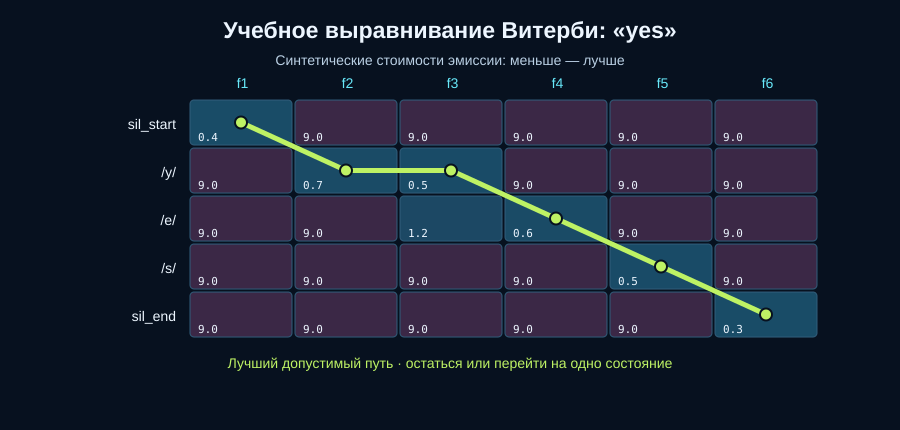

In [9]:
display(SVG(filename=str(LAB_ROOT / "outputs" / "viterbi_trellis.svg")))

## Часть B. Биграммная языковая модель

Обучаем модель на `toy_lm_corpus.txt` (7 предложений) с `k = 0.5`.

In [10]:
from scripts.bigram_lm import BigramLM, tokenize

corpus = (LAB_ROOT / "data" / "toy_lm_corpus.txt").read_text(encoding="utf-8").splitlines()
lm = BigramLM.train(corpus, k=0.5)

print("Слова корпуса:", sorted({w for s in corpus for w in tokenize(s)}))
print("Размер словаря |V| (вместе с <unk> и </s>):", len(lm.vocabulary))
print("k * |V| =", lm.k * len(lm.vocabulary))

Слова корпуса: ['coffee', 'drink', 'green', 'like', 'strong', 'tea', 'they', 'we']
Размер словаря |V| (вместе с <unk> и </s>): 10
k * |V| = 5.0


**Размер словаря.** В корпусе 8 разных слов: `we, they, drink, like, green, strong, tea, coffee`. Считая `<unk>` и `</s>` получается |V| = 10. Значит, в знаменателе `k·|V| = 0.5 · 10 = 5`.

**Подсчет для одного контекста.** Контекст `drink` встречается 4 раза: `drink green` в предложениях 1, 2 и 7 (3 раза) и `drink strong` в предложении 5 (1 раз). Значит, `C(drink) = 4`.

- `P(green | drink) = (3 + 0.5) / (4 + 5) = 3.5 / 9 ≈ 0.3889`
- `P(strong | drink) = (1 + 0.5) / (4 + 5) = 1.5 / 9 ≈ 0.1667`
- `P(tea | drink)`: такой биграммы в корпусе нет, поэтому `(0 + 0.5) / (4 + 5) = 0.5 / 9 ≈ 0.0556`

Проверим, что насчитали и то, что `</s>` учитывается, а незнакомое слово заменяется на `<unk>`.

In [7]:
context = "drink"
print(f"C({context}) =", lm.context_counts[context])
for w in ["green", "strong", "tea"]:
    print(f"C({context}, {w}) = {lm.bigram_counts[(context, w)]},  P({w} | {context}) = {lm.bigram_probability(context, w):.4f}")

total = sum(lm.bigram_probability(context, w) for w in lm.vocabulary)
print("Сумма P(· | drink) по всему словарю:", round(total, 6))
print()

print("P(</s> | tea)    =", lm.bigram_probability("tea", "</s>"))
print("P(<unk> | green) =", lm.bigram_probability("green", "<unk>"))
print("P(juice | green) =", lm.bigram_probability("green", "juice"), " (juice нет в словаре, значит это <unk>)")
print("logprob('we drink green juice') =", round(lm.sentence_logprob("we drink green juice"), 6))

C(drink) = 4
C(drink, green) = 3,  P(green | drink) = 0.3889
C(drink, strong) = 1,  P(strong | drink) = 0.1667
C(drink, tea) = 0,  P(tea | drink) = 0.0556
Сумма P(· | drink) по всему словарю: 1.0

P(</s> | tea)    = 0.55
P(<unk> | green) = 0.05
P(juice | green) = 0.05  (juice нет в словаре, значит это <unk>)
logprob('we drink green juice') = -3.693476


Сумма вероятностей по всему словарю равна 1. `P(juice | green)` совпадает с `P(<unk> | green)`, значит неизвестное слово превращается в `<unk>`. А `P(</s> | tea) = 5.5 / 10 = 0.55` значит, что конец предложения предсказывается как обычный токен.

**Оценки языковой модели для кандидатов**

In [12]:
candidates = json.loads((LAB_ROOT / "data" / "toy_candidate_scores.json").read_text(encoding="utf-8"))
for c in candidates:
    print(f"{c['candidate_id']:<20}{c['transcript']:<25}lm_log_score = {lm.sentence_logprob(c['transcript']):.6f}")

acoustic_favorite   we drink strong coffee   lm_log_score = -2.654739
language_favorite   we drink green tea       lm_log_score = -1.911720


«we drink green tea»:

| Биграмма | Формула | Вероятность |
|---|---|---|
| `<s> → we` | (4 + 0.5) / (7 + 5) | 0.3750 |
| `we → drink` | (2 + 0.5) / (4 + 5) | 0.2778 |
| `drink → green` | (3 + 0.5) / (4 + 5) | 0.3889 |
| `green → tea` | (5 + 0.5) / (5 + 5) | 0.5500 |
| `tea → </s>` | (5 + 0.5) / (5 + 5) | 0.5500 |

`log10` от произведения дает **−1.911720**. Для «we drink strong coffee» вероятности на `strong` и `coffee` меньше (`drink → strong` = 1.5/9, `strong → coffee` и `coffee → </s>` по 2.5/7), и получается **−2.654739**. В корпусе «green tea» встречается 5 раз, а «strong coffee» только 2.

## Часть C. Объединение акустических и языковых оценок

`combined_log_score = acoustic_log_score + λ · lm_log_score`. Сравниваем ранжирование при λ = 0, 0.5 и 1.0.

In [17]:
with open(LAB_ROOT / "outputs" / "candidate_scores.csv", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

print(f"{'λ':<6}{'№':<7}{'кандидат':<20}{'акуст.':>10}{'язык.':>12}{'объед.':>15}")
for r in rows:
    print(f"{r['lm_weight']:<6}{r['rank']:<7}{r['candidate_id']:<20}{float(r['acoustic_log_score']):>10.6f}{float(r['lm_log_score']):>12.6f}{float(r['combined_log_score']):>15.6f}")

print()
print(summary["candidate_rankings"])

λ     №      кандидат                акуст.       язык.         объед.
0.00  1      acoustic_favorite    -1.000000   -2.654739      -1.000000
0.00  2      language_favorite    -1.200000   -1.911720      -1.200000
0.50  1      language_favorite    -1.200000   -1.911720      -2.155860
0.50  2      acoustic_favorite    -1.000000   -2.654739      -2.327369
1.00  1      language_favorite    -1.200000   -1.911720      -3.111720
1.00  2      acoustic_favorite    -1.000000   -2.654739      -3.654739

{'0.0': ['acoustic_favorite', 'language_favorite'], '0.5': ['language_favorite', 'acoustic_favorite'], '1.0': ['language_favorite', 'acoustic_favorite']}


При λ = 0 языковая модель не влияет на результат, ранжирование определяется акустикой: на первом месте `acoustic_favorite` («we drink strong coffee») с оценкой −1.000000, на втором `language_favorite` («we drink green tea») с −1.200000.

При λ = 0.5 на первом месте оказывается `language_favorite` (−2.155860), на втором `acoustic_favorite` (−2.327369). У `acoustic_favorite` акустическая оценка лучше, но его языковая заметно хуже (−2.654739 против −1.911720).

При λ = 1.0  `language_favorite`(−3.111720) снова выше, чем `acoustic_favorite` (−3.654739). Разрыв увеличивается с 0.17 до 0.54, вклад языковой модели растет вместе с весом.

## Вопросы:

**1. Найдите в `viterbi_trellis.svg` две ячейки «кадр/состояние» с низкой стоимостью и одну с высокой. Что кодирует тепловая карта?**

Строки карты - это состояния (`sil_start, /y/, /e/, /s/, sil_end`), столбцы - это кадры (f1…f6). Числа - стоимость эмиссии. Синий цвет - маленькая стоимость, фиолетовый - большая.

- Низкая стоимость: кадр f1 / `sil_start` - **0.4**; кадр f6 / `sil_end` - **0.3**.
- Высокая стоимость: кадр f2 / `sil_start` - **9.0**.

**2. Проследите путь, выделенный зелёным цветом. Покажите один переход с сохранением состояния и один переход в следующее состояние.**

Зеленый путь: `sil_start (f1) → /y/ (f2) → /y/ (f3) → /e/ (f4) → /s/ (f5) → sil_end (f6)`.

- Сохранение состояния: f2 → f3, путь остается в `/y/`.
- Переход в следующее состояние: например, f1 → f2, путь идет из `sil_start` в `/y/`.

**3. Сравните стоимость лучшего пути со стоимостью альтернативного, сославшись на соответствующие строки в `alignment_path.csv` или данные в `summary.json`.**

В `summary.json`: alignment_total_cost = 3.0, alternative_path_cost = 3.7. В `alignment_path.csv` накопленная стоимость в последней строке (f6) равна 3.000. Разница 0.7 набирается на кадре f3: лучший путь стоит в `/y/` с эмиссией 0.5, а альтернативный - в `/e/` с эмиссией 1.2. На остальных кадрах пути совпадают по стоимости.

**4. Для `λ=0` и `λ=0.5` укажите гипотезу-кандидата на первом месте и его акустическую, языковую и объединенную логарифмические оценки из `candidate_scores.csv`.**

- λ = 0: первое место у `acoustic_favorite` («we drink strong coffee»). Акустическая −1.000000, языковая −2.654739, объединенная −1.000000.
- λ = 0.5: первое место у `language_favorite` («we drink green tea»). Акустическая −1.200000, языковая −1.911720, объединенная −2.155860.

**5. Почему кандидат на первом месте меняется (или не меняется) с изменением λ?**

При λ = 0 языковая модель не учитывается, остается только акустикческая, и выигрывает `acoustic_favorite`, потому что у нее акустическая оценка выше на 0.2. Но у `language_favorite` языковая оценка лучше на 2.654739 − 1.911720 = 0.743019. Разница объединенных оценок `language_favorite` и `acoustic_favorite` равна −0.2 + 0.743·λ. Она становится положительной при λ > 0.2 / 0.743 ≈ **0.27**. Поэтому при λ = 0.5 и λ = 1.0 первой оказывается `language_favorite`. При λ = 0.5 разница равна −2.155860 − (−2.327369) ≈ 0.17 в пользу `language_favorite`.